## Create a Granta MI Session

Import the GRANTA_MIScriptingToolkit package, and create a connection to a Granta MI server.

In [1]:
import datetime
import GRANTA_MIScriptingToolkit as gdl
from GRANTA_MIScriptingToolkit import granta as mpy
import numpy as np
import matplotlib.pyplot as plt
from tabulate import tabulate
import pandas as pd

usernameVal = 'STK_user'
passwordVal = 'P455w07d!'

session = mpy.connect('https://nanomecommons.grantami.com/mi_servicelayer', user_name=usernameVal, password=passwordVal)

## Get all records (number/table)

+---------------------------------+---------------------+
| Table Name                      |   Number of Records |
+=================================+=====================+
| Materials                       |                  39 |
+---------------------------------+---------------------+
| Material Batches                |                  60 |
+---------------------------------+---------------------+
| Specimens                       |                 106 |
+---------------------------------+---------------------+
| Indentation test data           |                  18 |
+---------------------------------+---------------------+
| FIB-DIC test data               |                  26 |
+---------------------------------+---------------------+
| SEM-EDX test data               |                   3 |
+---------------------------------+---------------------+
| AFM test data                   |                   1 |
+---------------------------------+---------------------+
| XRD test dat

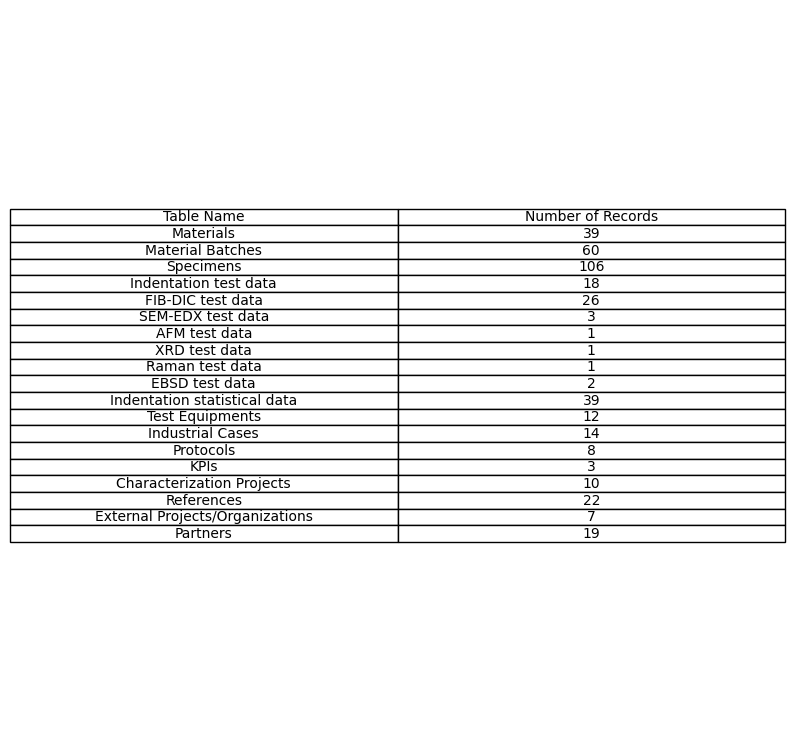

Total number of records in the database: 391


In [2]:
dbKey = "MI_Blank_v2021"
tableName = "Partners"

db = session.get_db(db_key=dbKey)

data_tables = [
    "Materials",
    "Material Batches",
    "Specimens",
    "Indentation test data",
    "FIB-DIC test data",
    "SEM-EDX test data",
    "AFM test data",
    "XRD test data",
    "Raman test data",
    "EBSD test data",
    "Indentation statistical data",
    "Test Equipments",
    "Industrial Cases",
    "Protocols",
    "KPIs",
    "Characterization Projects",
    "References",
    "External Projects/Organizations",
    "Partners"
]

# Collect data for the table
table_data = []
for tableName in data_tables:
    table = db.get_table(tableName)
    record_count = len(table.all_records())
    table_data.append([tableName, record_count])

# Print the table
headers = ["Table Name", "Number of Records"]
print(tabulate(table_data, headers, tablefmt="grid"))

# Create a table using matplotlib
fig, ax = plt.subplots(figsize=(10, len(table_data) * 0.5))  # Adjust the size as needed
ax.axis('tight')
ax.axis('off')
table = ax.table(cellText=table_data, colLabels=headers, cellLoc='center', loc='center')

# Save the table as an image
plt.savefig("table_image.png", bbox_inches='tight', dpi=300)
plt.show()

# Print the total number of records in the database
total_records = sum([len(db.get_table(table).all_records()) for table in data_tables])
print(f"Total number of records in the database: {total_records}")


Name                           -    Type    -    Unit    -   Meta?    -   Meta-attributes    -    Column headers   
-------------------------------------------------------------------------------------------------------------------
Contact depth (mean)           -    POIN    -     nm     -   False    - {'Maximum': <Attribu
Peak load (mean)               -    POIN    -     N      -   False    - {'Maximum': <Attribu
Stiffness (mean)               -    POIN    -    N/nm    -   False    - {'Maximum': <Attribu
Contact area (mean)            -    POIN    -    nm^2    -   False    - {'Maximum': <Attribu
Reduced elastic modulus (mean) -    POIN    -    GPa     -   False    - {'Maximum': <Attribu
Hardness (mean)                -    POIN    -    GPa     -   False    - {'Maximum': <Attribu
Test equipment ID              -    STXT    -            -   False    -          {}         
Manufacturer                   -    STXT    -            -   False    -          {}         
Model                   

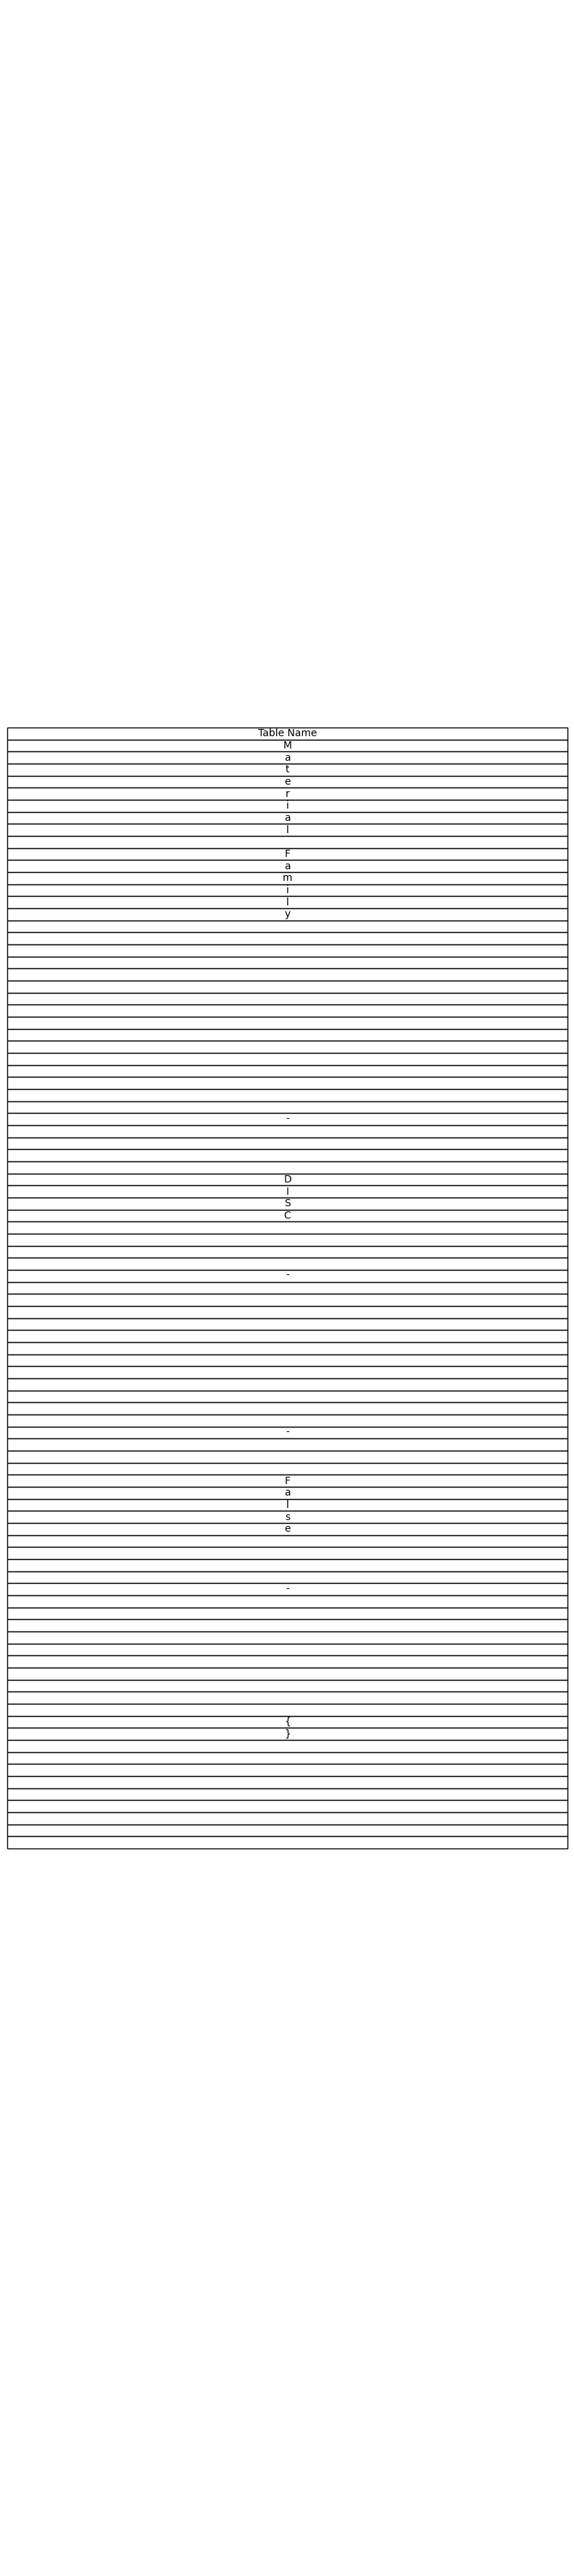

In [4]:
# Connect to the database
tableName = "Indentation test data"
layoutName = "Indentation test data"
recordName = "SiNx CSM High-Speed"

db = session.get_db(db_key=dbKey)
tab = db.get_table(tableName)
indentation_layout = tab.layouts[layoutName]
indentation_layout.categories
attributes_by_category = indentation_layout.attributes_by_category
record = tab.search_for_records_by_name(recordName)[0]

data = []
for category, attributes in attributes_by_category.items():
    for attribute in attributes:
        data.append([category, attribute])

df = pd.DataFrame(data, columns=['Categories', 'Attributes'])

# Print the list of all attributes in the table
print('{:30.30} - {:^10.10} - {:^10.10} - {:^10.10} - {:^20.20} - {:^20.20}'.format('Name', 'Type', 'Unit', 'Meta?', 'Meta-attributes', 'Column headers'))
print('-'*115)
for name, att in tab.attributes.items():
    if att.type == 'FUNC':
        func = record.attributes[name]
        output = '{:30.30} - {:^10.10} - {:^10.10} - {:^10.10} - {:^20.20} - {:^20.20}'.format(name, att.type, att.unit, str(att.is_meta), str(att.meta_attributes), str(func.column_headers))
        print(output)
    elif att.type == 'TABL':
        hist = record.attributes[name]
        output = '{:30.30} - {:^10.10} - {:^10.10} - {:^10.10} - {:^20.20} - {:^20.20}'.format(name, att.type, att.unit, str(att.is_meta), str(att.meta_attributes), str(hist.columns))
        print(output)
    else:
        output = '{:30.30} - {:^10.10} - {:^10.10} - {:^10.10} - {:^20.20}'.format(name, att.type, att.unit, str(att.is_meta), str(att.meta_attributes))
        print(output)



